In [ ]:
!pip -q install torch torchvision scikit-learn seaborn matplotlib pandas pillow

In [ ]:
import os
import json
import time
import copy
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    average_precision_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Training will run on CPU.")

Device: cuda
GPU: Tesla T4


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
from pathlib import Path

ROOT = Path(path)

training_candidates = list(ROOT.rglob("Training"))
testing_candidates = list(ROOT.rglob("Testing"))

if not training_candidates or not testing_candidates:
    raise FileNotFoundError(
        "Could not find Training and Testing folders. "
        "Inspect the folders printed in Cell 3."
    )

TRAIN_DIR = training_candidates[0]
TEST_DIR = testing_candidates[0]

print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)
print("Training classes:", sorted(
    p.name for p in TRAIN_DIR.iterdir() if p.is_dir()
))
print("Testing classes:", sorted(
    p.name for p in TEST_DIR.iterdir() if p.is_dir()
))

Training directory: /kaggle/input/brain-tumor-mri-dataset/Training
Testing directory: /kaggle/input/brain-tumor-mri-dataset/Testing
Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training images: 5600
Testing images: 1600


,Training image count
glioma,1400
meningioma,1400
notumor,1400
pituitary,1400


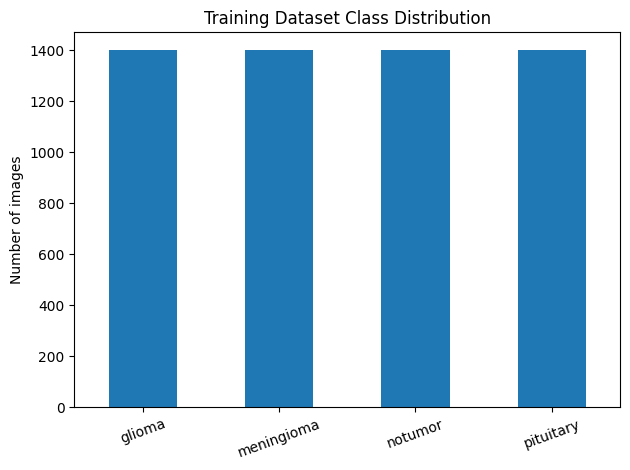

In [ ]:
from torchvision import datasets
import pandas as pd
import matplotlib.pyplot as plt

train_preview = datasets.ImageFolder(str(TRAIN_DIR))
test_preview = datasets.ImageFolder(str(TEST_DIR))

class_names = train_preview.classes

print("Classes:", class_names)
print("Class mapping:", train_preview.class_to_idx)
print("Training images:", len(train_preview))
print("Testing images:", len(test_preview))

assert train_preview.classes == test_preview.classes, (
    "Training and testing class folders do not match."
)

counts = pd.Series(
    [class_names[label] for _, label in train_preview.samples]
).value_counts().reindex(class_names, fill_value=0)

display(counts.rename("Training image count").to_frame())

counts.plot(kind="bar", title="Training Dataset Class Distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)
print("Output classes:", class_names)

Number of classes: 4
Output classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
import os
import copy
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 224 x 224
Batch size: 32


In [ ]:
class TransformSubset(Dataset):
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        actual_index = self.indices[index]
        image, label = self.base_dataset[actual_index]

        if self.transform:
            image = self.transform(image)

        return image, label


base_train_dataset = datasets.ImageFolder(str(TRAIN_DIR))
base_test_dataset = datasets.ImageFolder(str(TEST_DIR))

assert base_train_dataset.classes == base_test_dataset.classes

targets = np.array(base_train_dataset.targets)
all_indices = np.arange(len(targets))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=targets
)

train_dataset = TransformSubset(
    base_train_dataset,
    train_indices,
    train_transform
)

val_dataset = TransformSubset(
    base_train_dataset,
    val_indices,
    eval_transform
)

test_dataset = datasets.ImageFolder(
    str(TEST_DIR),
    transform=eval_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", class_names)

Training images: 4480
Validation images: 1120
Testing images: 1600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


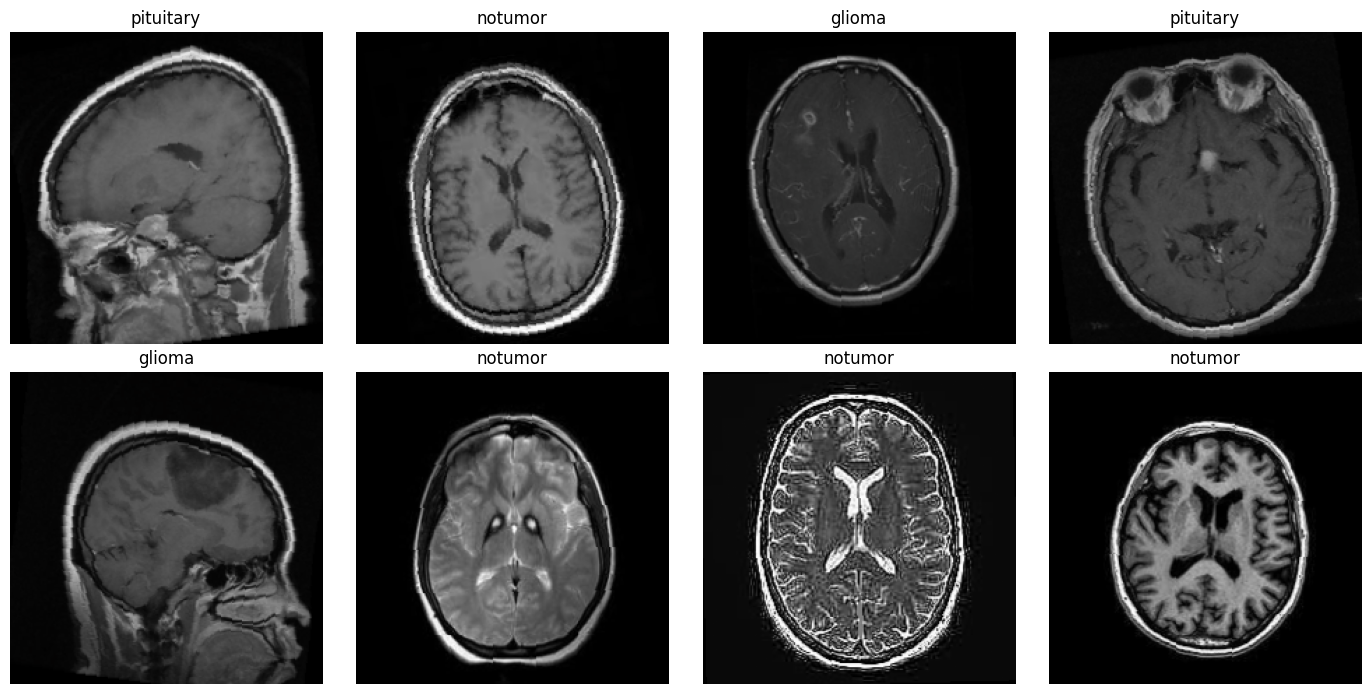

In [ ]:
def show_images(dataset, class_names, number=8):
    number = min(number, len(dataset))

    fig, axes = plt.subplots(
        2, (number + 1) // 2,
        figsize=(14, 7)
    )
    axes = np.array(axes).reshape(-1)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    for i in range(number):
        image, label = dataset[i]

        image = image * std + mean
        image = image.clamp(0, 1).permute(1, 2, 0).numpy()

        axes[i].imshow(image)
        axes[i].set_title(class_names[label])
        axes[i].axis("off")

    for i in range(number, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_images(train_dataset, class_names, number=8)

In [ ]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


custom_cnn = CustomCNN(NUM_CLASSES).to(device)

print(custom_cnn)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, af

In [ ]:
try:
    resnet_weights = models.ResNet18_Weights.DEFAULT
    resnet18 = models.resnet18(weights=resnet_weights)
    print("ResNet18 loaded with pretrained weights.")

except Exception as e:
    print("Could not load pretrained weights:", e)
    print("Using randomly initialized ResNet18.")
    resnet18 = models.resnet18(weights=None)

resnet18.fc = nn.Linear(
    resnet18.fc.in_features,
    NUM_CLASSES
)

resnet18 = resnet18.to(device)

print("ResNet18 output classes:", NUM_CLASSES)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 84.1MB/s]


ResNet18 loaded with pretrained weights.
ResNet18 output classes: 4


In [ ]:
try:
    mobilenet_weights = models.MobileNet_V3_Small_Weights.DEFAULT
    mobilenet = models.mobilenet_v3_small(weights=mobilenet_weights)
    print("MobileNetV3 loaded with pretrained weights.")

except Exception as e:
    print("Could not load pretrained weights:", e)
    print("Using randomly initialized MobileNetV3.")
    mobilenet = models.mobilenet_v3_small(weights=None)

in_features = mobilenet.classifier[3].in_features

mobilenet.classifier[3] = nn.Linear(
    in_features,
    NUM_CLASSES
)

mobilenet = mobilenet.to(device)

print("MobileNetV3 output classes:", NUM_CLASSES)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 66.1MB/s]


MobileNetV3 loaded with pretrained weights.
MobileNetV3 output classes: 4


In [ ]:
def train_model(model, train_loader, val_loader,
                epochs=10, learning_rate=0.001):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    best_val_accuracy = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # Training
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        # Validation
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_running_loss / val_total
        val_accuracy = val_correct / val_total

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

    model.load_state_dict(best_weights)

    elapsed = (time.time() - start_time) / 60

    print(f"\nBest validation accuracy: {best_val_accuracy:.4f}")
    print(f"Training time: {elapsed:.2f} minutes")

    return model, history

In [ ]:
EPOCHS = 10
LEARNING_RATE = 0.001

# Instantiate PyTorch DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

custom_cnn, cnn_history = train_model(
    custom_cnn,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE
)

Epoch [1/10] Train Loss: 0.8219 | Train Acc: 0.6748 | Val Loss: 1.5539 | Val Acc: 0.3929
Epoch [2/10] Train Loss: 0.6652 | Train Acc: 0.7386 | Val Loss: 2.5016 | Val Acc: 0.4446
Epoch [3/10] Train Loss: 0.5735 | Train Acc: 0.7761 | Val Loss: 0.5800 | Val Acc: 0.7991
Epoch [4/10] Train Loss: 0.5449 | Train Acc: 0.7922 | Val Loss: 0.6175 | Val Acc: 0.7196
Epoch [5/10] Train Loss: 0.4922 | Train Acc: 0.8112 | Val Loss: 0.7007 | Val Acc: 0.7161
Epoch [6/10] Train Loss: 0.4853 | Train Acc: 0.8219 | Val Loss: 1.0589 | Val Acc: 0.6098
Epoch [7/10] Train Loss: 0.4384 | Train Acc: 0.8393 | Val Loss: 0.3455 | Val Acc: 0.8714
Epoch [8/10] Train Loss: 0.4250 | Train Acc: 0.8366 | Val Loss: 0.4459 | Val Acc: 0.8429
Epoch [9/10] Train Loss: 0.3897 | Train Acc: 0.8556 | Val Loss: 0.3444 | Val Acc: 0.8679
Epoch [10/10] Train Loss: 0.3841 | Train Acc: 0.8569 | Val Loss: 0.9784 | Val Acc: 0.6107

Best validation accuracy: 0.8714
Training time: 4.87 minutes


In [ ]:
resnet18, resnet_history = train_model(
    resnet18,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=0.0001
)

Epoch [1/10] Train Loss: 0.2715 | Train Acc: 0.8998 | Val Loss: 0.1159 | Val Acc: 0.9661
Epoch [2/10] Train Loss: 0.0969 | Train Acc: 0.9674 | Val Loss: 0.0701 | Val Acc: 0.9759
Epoch [3/10] Train Loss: 0.0545 | Train Acc: 0.9812 | Val Loss: 0.0651 | Val Acc: 0.9830
Epoch [4/10] Train Loss: 0.0340 | Train Acc: 0.9906 | Val Loss: 0.0484 | Val Acc: 0.9804
Epoch [5/10] Train Loss: 0.0257 | Train Acc: 0.9938 | Val Loss: 0.0615 | Val Acc: 0.9839
Epoch [6/10] Train Loss: 0.0365 | Train Acc: 0.9871 | Val Loss: 0.0824 | Val Acc: 0.9714
Epoch [7/10] Train Loss: 0.0272 | Train Acc: 0.9908 | Val Loss: 0.0544 | Val Acc: 0.9804
Epoch [8/10] Train Loss: 0.0173 | Train Acc: 0.9935 | Val Loss: 0.0297 | Val Acc: 0.9893
Epoch [9/10] Train Loss: 0.0108 | Train Acc: 0.9973 | Val Loss: 0.0407 | Val Acc: 0.9866
Epoch [10/10] Train Loss: 0.0097 | Train Acc: 0.9969 | Val Loss: 0.0389 | Val Acc: 0.9884

Best validation accuracy: 0.9893
Training time: 4.94 minutes


In [ ]:
mobilenet, mobilenet_history = train_model(
    mobilenet,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=0.0001
)

Epoch [1/10] Train Loss: 0.5290 | Train Acc: 0.8232 | Val Loss: 0.7359 | Val Acc: 0.7179
Epoch [2/10] Train Loss: 0.2256 | Train Acc: 0.9161 | Val Loss: 0.5306 | Val Acc: 0.7688
Epoch [3/10] Train Loss: 0.1567 | Train Acc: 0.9420 | Val Loss: 0.2264 | Val Acc: 0.9152
Epoch [4/10] Train Loss: 0.1213 | Train Acc: 0.9569 | Val Loss: 0.2072 | Val Acc: 0.9116
Epoch [5/10] Train Loss: 0.0758 | Train Acc: 0.9746 | Val Loss: 0.1381 | Val Acc: 0.9482
Epoch [6/10] Train Loss: 0.0625 | Train Acc: 0.9792 | Val Loss: 0.0979 | Val Acc: 0.9589
Epoch [7/10] Train Loss: 0.0578 | Train Acc: 0.9781 | Val Loss: 0.0660 | Val Acc: 0.9741
Epoch [8/10] Train Loss: 0.0416 | Train Acc: 0.9855 | Val Loss: 0.0671 | Val Acc: 0.9759
Epoch [9/10] Train Loss: 0.0295 | Train Acc: 0.9897 | Val Loss: 0.1351 | Val Acc: 0.9527
Epoch [10/10] Train Loss: 0.0287 | Train Acc: 0.9904 | Val Loss: 0.1071 | Val Acc: 0.9696

Best validation accuracy: 0.9759
Training time: 4.39 minutes


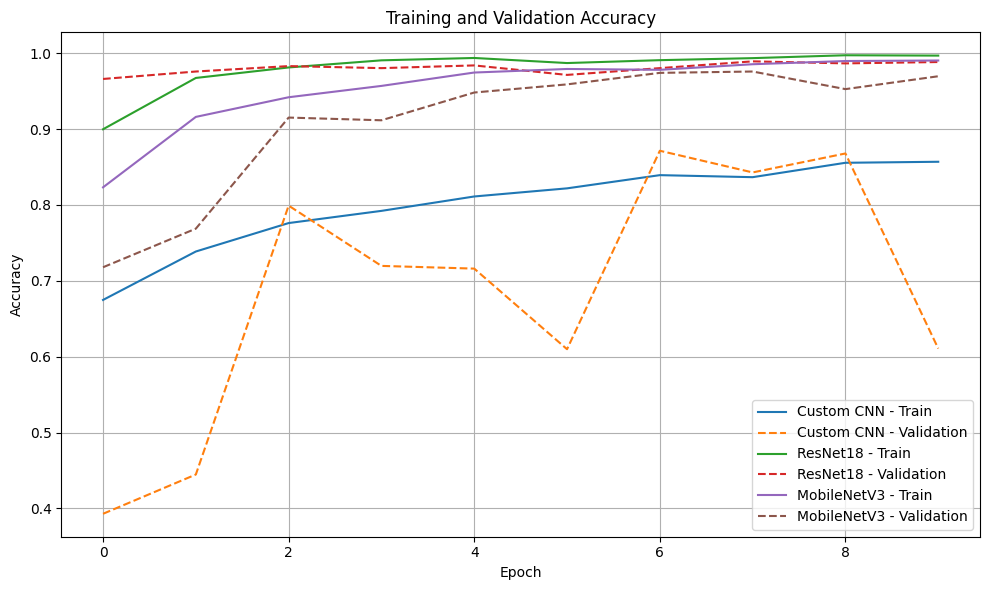

In [ ]:
histories = {
    "Custom CNN": cnn_history,
    "ResNet18": resnet_history,
    "MobileNetV3": mobilenet_history
}

plt.figure(figsize=(10, 6))

for model_name, history in histories.items():
    plt.plot(
        history["train_accuracy"],
        label=f"{model_name} - Train"
    )
    plt.plot(
        history["val_accuracy"],
        linestyle="--",
        label=f"{model_name} - Validation"
    )

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

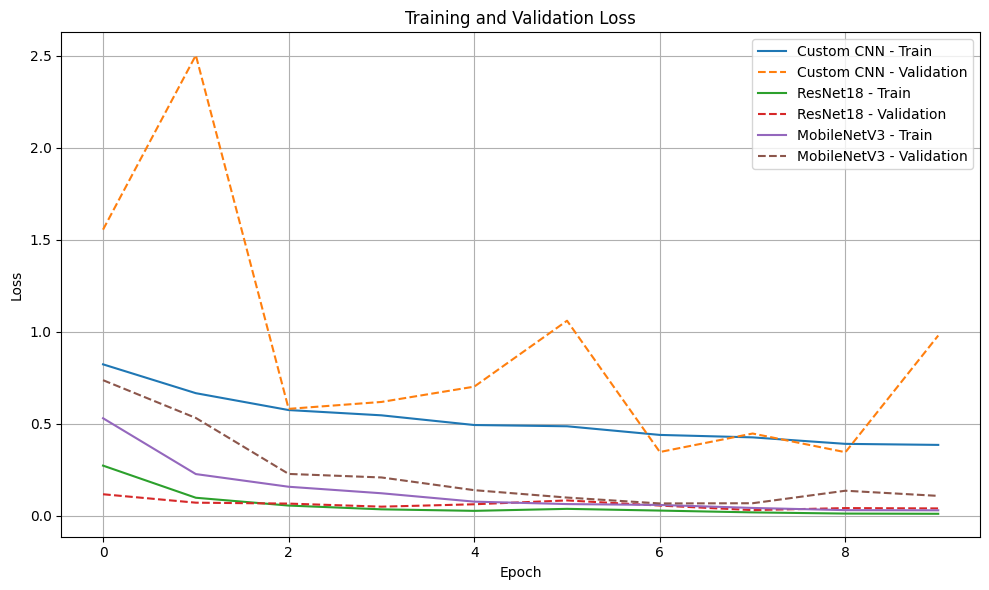

In [ ]:
plt.figure(figsize=(10, 6))

for model_name, history in histories.items():
    plt.plot(
        history["train_loss"],
        label=f"{model_name} - Train"
    )
    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{model_name} - Validation"
    )

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_model(model, test_loader, class_names):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )
    recall = recall_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    print(f"Test Accuracy:  {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1-score:  {f1:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names)))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display.plot(cmap="Blues", xticks_rotation=30)
    plt.title("Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "probabilities": np.array(all_probabilities),
        "confusion_matrix": cm
    }

CUSTOM CNN
Test Accuracy:  0.7875
Macro Precision: 0.8025
Macro Recall:    0.7875
Macro F1-score:  0.7778

Classification Report:

              precision    recall  f1-score   support

      glioma       0.93      0.63      0.75       400
  meningioma       0.73      0.56      0.64       400
     notumor       0.70      0.99      0.82       400
   pituitary       0.85      0.96      0.90       400

    accuracy                           0.79      1600
   macro avg       0.80      0.79      0.78      1600
weighted avg       0.80      0.79      0.78      1600



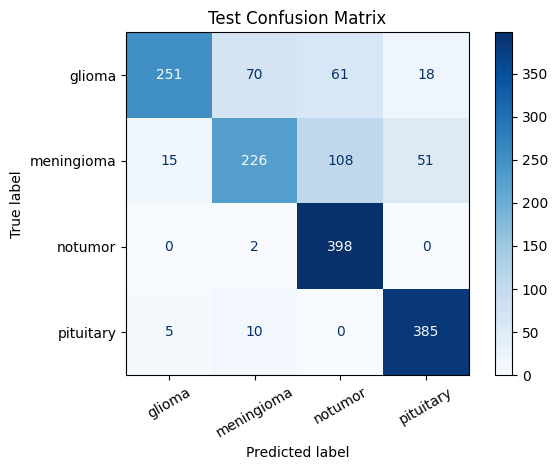

RESNET18
Test Accuracy:  0.9475
Macro Precision: 0.9509
Macro Recall:    0.9475
Macro F1-score:  0.9462

Classification Report:

              precision    recall  f1-score   support

      glioma       0.99      0.81      0.89       400
  meningioma       0.91      0.98      0.94       400
     notumor       0.91      1.00      0.95       400
   pituitary       0.99      1.00      0.99       400

    accuracy                           0.95      1600
   macro avg       0.95      0.95      0.95      1600
weighted avg       0.95      0.95      0.95      1600



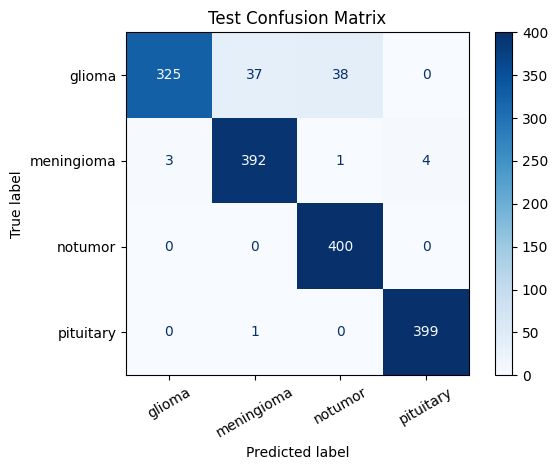

MOBILENETV3
Test Accuracy:  0.9394
Macro Precision: 0.9428
Macro Recall:    0.9394
Macro F1-score:  0.9379

Classification Report:

              precision    recall  f1-score   support

      glioma       0.98      0.80      0.88       400
  meningioma       0.88      0.97      0.93       400
     notumor       0.92      1.00      0.96       400
   pituitary       0.99      0.99      0.99       400

    accuracy                           0.94      1600
   macro avg       0.94      0.94      0.94      1600
weighted avg       0.94      0.94      0.94      1600



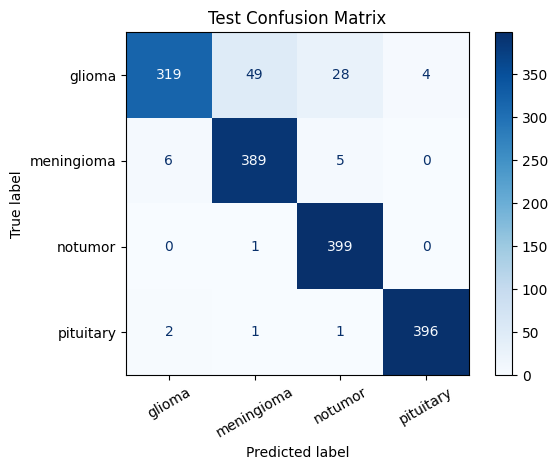

In [ ]:
# Instantiate the PyTorch DataLoader for testing
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

print("=" * 50)
print("CUSTOM CNN")
print("=" * 50)
cnn_results = evaluate_model(
    custom_cnn, test_loader, class_names
)

print("=" * 50)
print("RESNET18")
print("=" * 50)
resnet_results = evaluate_model(
    resnet18, test_loader, class_names
)

print("=" * 50)
print("MOBILENETV3")
print("=" * 50)
mobilenet_results = evaluate_model(
    mobilenet, test_loader, class_names
)

In [ ]:
# Multiclass ROC Curves (One-vs-Rest) for all evaluated models
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarize true labels for multiclass One-vs-Rest ROC analysis
y_test_bin = label_binarize(cnn_results["labels"], classes=list(range(NUM_CLASSES)))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_eval = [
    ("Custom CNN", cnn_results),
    ("ResNet18", resnet_results),
    ("MobileNetV3", mobilenet_results)
]

for ax, (model_name, res) in zip(axes, models_eval):
    probs = res["probabilities"]
    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=2, label=f"{class_name} (AUC = {roc_auc:.3f})")
    
    ax.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", alpha=0.7)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curves - {model_name}")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("Multiclass ROC Analysis across Architectures (One-vs-Rest)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()


In [ ]:
results_table = pd.DataFrame([
    {
        "Model": "Custom CNN",
        "Accuracy": cnn_results["accuracy"],
        "Precision": cnn_results["precision"],
        "Recall": cnn_results["recall"],
        "F1-score": cnn_results["f1_score"]
    },
    {
        "Model": "ResNet18",
        "Accuracy": resnet_results["accuracy"],
        "Precision": resnet_results["precision"],
        "Recall": resnet_results["recall"],
        "F1-score": resnet_results["f1_score"]
    },
    {
        "Model": "MobileNetV3",
        "Accuracy": mobilenet_results["accuracy"],
        "Precision": mobilenet_results["precision"],
        "Recall": mobilenet_results["recall"],
        "F1-score": mobilenet_results["f1_score"]
    }
])

display(
    results_table.sort_values(
        by="F1-score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-score
0,ResNet18,0.947500,0.950929,0.947500,0.946181
1,MobileNetV3,0.939375,0.942776,0.939375,0.937938
2,Custom CNN,0.787500,0.802481,0.787500,0.777840


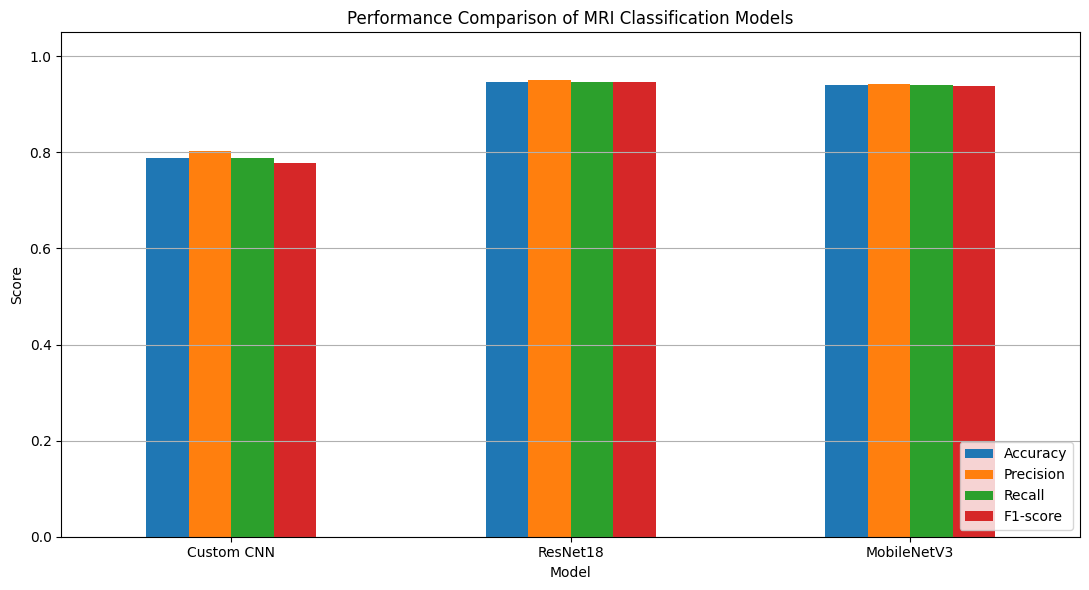

In [ ]:
results_table.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Performance Comparison of MRI Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("/content/saved_models", exist_ok=True)

torch.save(
    custom_cnn.state_dict(),
    "/content/saved_models/custom_cnn.pth"
)

torch.save(
    resnet18.state_dict(),
    "/content/saved_models/resnet18.pth"
)

torch.save(
    mobilenet.state_dict(),
    "/content/saved_models/mobilenetv3.pth"
)

print("All model weights saved successfully.")

All model weights saved successfully.


Saving download.jfif to download.jfif


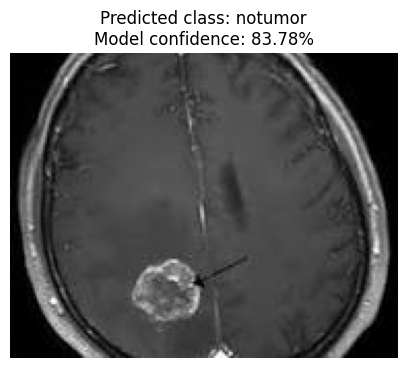

,Class,Probability (%)
2,notumor,83.779999
1,meningioma,15.340000
3,pituitary,0.860000
0,glioma,0.020000


In [ ]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

def predict_mri(image_path, model, class_names):
    image = Image.open(image_path).convert("RGB")
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    predicted_class = class_names[predicted_index]
    confidence = probabilities[predicted_index].item() * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Predicted class: {predicted_class}\n"
        f"Model confidence: {confidence:.2f}%"
    )
    plt.axis("off")
    plt.show()

    probability_table = pd.DataFrame({
        "Class": class_names,
        "Probability (%)": (
            probabilities.cpu().numpy() * 100
        ).round(2)
    }).sort_values(
        "Probability (%)",
        ascending=False
    )

    display(probability_table)

    return predicted_class, confidence


predicted_class, confidence = predict_mri(
    image_path,
    resnet18,
    class_names
)

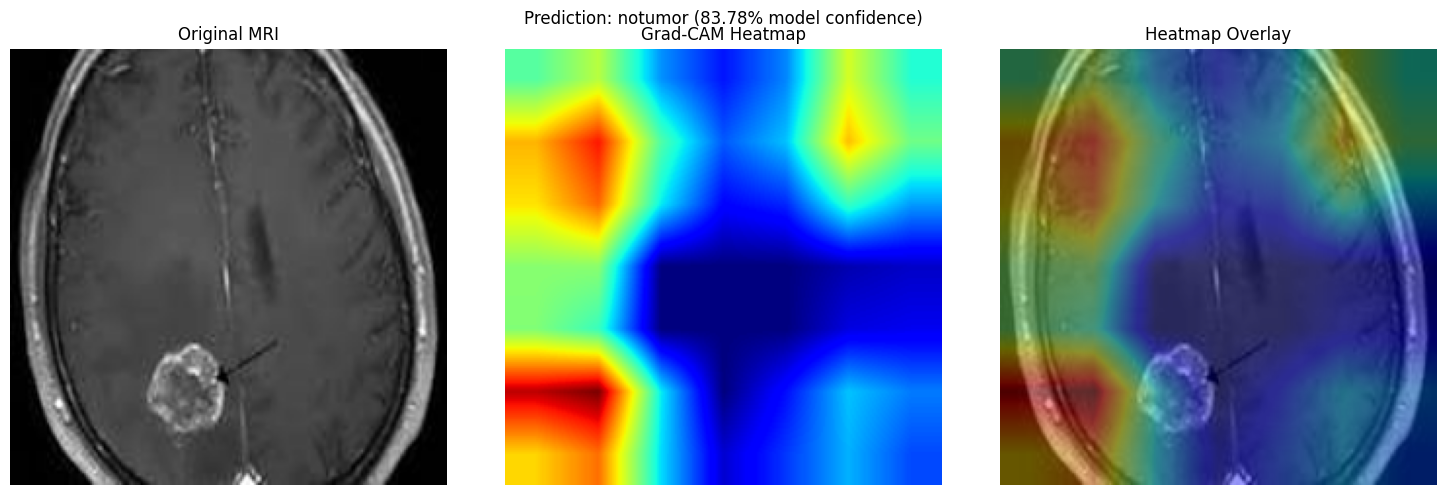

Predicted class: notumor
Model confidence: 83.78%


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def gradcam_resnet18(image_path, model, class_names):
    model.eval()

    image = Image.open(image_path).convert("RGB")
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    activations = []
    gradients = []

    target_layer = model.layer4[-1].conv2

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    try:
        model.zero_grad(set_to_none=True)

        output = model(input_tensor)
        predicted_index = output.argmax(dim=1).item()

        score = output[0, predicted_index]
        score.backward()

        activation = activations[0].detach()
        gradient = gradients[0].detach()

        weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activation).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())
        else:
            cam = np.zeros_like(cam)

        probabilities = torch.softmax(output.detach(), dim=1)[0]
        confidence = probabilities[predicted_index].item() * 100

        display_image = image.resize((IMG_SIZE, IMG_SIZE))
        display_image = np.asarray(display_image)

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        axes[0].imshow(display_image)
        axes[0].set_title("Original MRI")

        axes[1].imshow(cam, cmap="jet")
        axes[1].set_title("Grad-CAM Heatmap")

        axes[2].imshow(display_image)
        axes[2].imshow(cam, cmap="jet", alpha=0.4)
        axes[2].set_title("Heatmap Overlay")

        for ax in axes:
            ax.axis("off")

        plt.suptitle(
            f"Prediction: {class_names[predicted_index]} "
            f"({confidence:.2f}% model confidence)"
        )
        plt.tight_layout()
        plt.show()

        print("Predicted class:", class_names[predicted_index])
        print(f"Model confidence: {confidence:.2f}%")

    finally:
        forward_handle.remove()
        backward_handle.remove()


# Use the image uploaded in Cell 26
gradcam_resnet18(image_path, resnet18, class_names)

In [ ]:
import os

os.makedirs("/content/brain_tumor_results", exist_ok=True)

results_table.to_csv(
    "/content/brain_tumor_results/model_comparison.csv",
    index=False
)

display(results_table)

print("Model comparison saved successfully.")

,Model,Accuracy,Precision,Recall,F1-score
0,Custom CNN,0.787500,0.802481,0.787500,0.777840
1,ResNet18,0.947500,0.950929,0.947500,0.946181
2,MobileNetV3,0.939375,0.942776,0.939375,0.937938


Model comparison saved successfully.


In [ ]:
import json
import torch
import os

save_dir = "/content/brain_tumor_results"
os.makedirs(save_dir, exist_ok=True)

torch.save(
    custom_cnn.state_dict(),
    f"{save_dir}/custom_cnn.pth"
)

torch.save(
    resnet18.state_dict(),
    f"{save_dir}/resnet18.pth"
)

torch.save(
    mobilenet.state_dict(),
    f"{save_dir}/mobilenetv3.pth"
)

with open(f"{save_dir}/class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Saved model weights and class labels:")
print(os.listdir(save_dir))

Saved model weights and class labels:
['class_names.json', 'model_comparison.csv', 'mobilenetv3.pth', 'custom_cnn.pth', 'resnet18.pth']


In [2]:
import os
import shutil
from google.colab import files

target_dir = "/content/brain_tumor_results"
os.makedirs(target_dir, exist_ok=True)

zip_path = shutil.make_archive(
    target_dir,
    "zip",
    target_dir
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>